In [ ]:
# asdfasdf

# Download stock prices

Pulls daily OHLCV data from Yahoo Finance via `yfinance` and caches it to `data/`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

# yfinance still calls pandas methods with inplace=True (deprecated in pandas 3.1).
# Must come after `import yfinance`, which installs its own DeprecationWarning filter.
warnings.filterwarnings("ignore", category=pd.errors.Pandas4Warning, module="yfinance")

TICKERS = ["SPY", "QQQ", "TLT", "IEF", "GLD", "USO", "JNK"]
START = "2015-01-01"
END = None  # None = today

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

In [2]:
prices = yf.download(TICKERS, start=START, end=END, auto_adjust=True, group_by="ticker", progress=False)

for ticker in TICKERS:
    prices[ticker].dropna().to_csv(DATA_DIR / f"{ticker}.csv")

prices.tail()

Ticker             QQQ                                                \
Price             Open        High         Low       Close    Volume   
Date                                                                   
2026-10-19  719.609985  724.549988  716.570007  718.359985  37196700   
2026-10-20  715.250000  722.750000  710.390015  717.630005  30518500   
2026-10-21  722.219971  727.950012  719.710022  725.200012  32476200   
2026-10-22  713.609985  715.429993  701.900024  704.469971  64553400   
2026-10-23  702.200012  709.299988  701.159973  704.400024  30138000   

Ticker            TLT                                                    SPY  \
Price            Open       High        Low      Close    Volume        Open   
Date                                                                           
2026-10-19  79.900002  79.980003  79.339996  79.459999  30971200  767.229980   
2026-10-20  80.070000  80.370003  79.839996  80.129997  28471600  765.859985   
2026-10-21  80.320000  80.470001  79.839996  80.239998  36283000  771.169983   
2026-10-22  81.000000  81.919998  80.870003  81.739998  65635100  766.369995   
2026-10-23  81.790001  81.800003  81.269997  81.339996  35120900  759.900024   

Ticker                                                    
Price             High         Low       Close    Volume  
Date                                                      
2026-10-19  770.460022  765.820007  766.479980  38680100  
2026-10-20  772.289978  764.250000  769.049988  35048400  
2026-10-21  774.440002  768.400024  773.090027  31943800  
2026-10-22  767.710022  761.169983  763.960022  54117100  
2026-10-23  763.469971  758.679993  759.969971  33377700

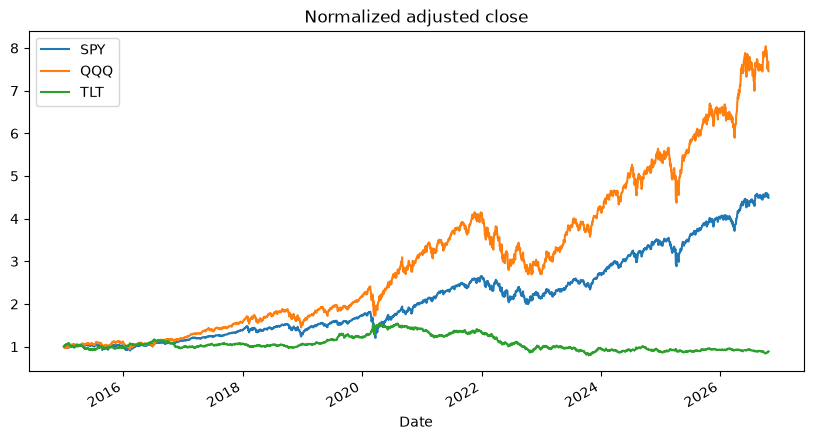

In [3]:
close = pd.DataFrame({t: prices[t]["Close"] for t in TICKERS}).dropna()
(close / close.iloc[0]).plot(figsize=(10, 5), title="Normalized adjusted close")
plt.show()

In [12]:
LOOKBACK = pd.Timedelta(days=30)  # calendar days

# Close on the last trading day on or before (date - 90 days)
past_close = close.reindex(close.index - LOOKBACK, method="ffill").set_axis(close.index)
trailing_90d = (close / past_close - 1).dropna()
trailing_90d.tail().style.format("{:.2%}")

,SPY,QQQ,TLT
Date,,,
2026-10-19 00:00:00,0.63%,-0.32%,-1.81%
2026-10-20 00:00:00,0.97%,-0.43%,-0.98%
2026-10-21 00:00:00,-0.05%,-2.19%,-1.51%
2026-10-22 00:00:00,-1.22%,-5.75%,0.39%
2026-10-23 00:00:00,-1.02%,-4.97%,1.50%


In [13]:
best_ticker = pd.DataFrame({
    "ticker": trailing_90d.idxmax(axis=1),
    "return": trailing_90d.max(axis=1),
})
best_ticker.tail().style.format({"return": "{:.2%}"})

,ticker,return
Date,,
2026-10-19 00:00:00,SPY,0.63%
2026-10-20 00:00:00,SPY,0.97%
2026-10-21 00:00:00,SPY,-0.05%
2026-10-22 00:00:00,TLT,0.39%
2026-10-23 00:00:00,TLT,1.50%


In [14]:
# Return from this close to the next close, for the ticker picked on this row
fwd_1d = close.pct_change().shift(-1)
best_ticker["fwd_1d_return"] = [fwd_1d.at[date, t] for date, t in best_ticker["ticker"].items()]
best_ticker.tail().style.format({"return": "{:.2%}", "fwd_1d_return": "{:.2%}"})

,ticker,return,fwd_1d_return
Date,,,
2026-10-19 00:00:00,SPY,0.63%,0.34%
2026-10-20 00:00:00,SPY,0.97%,0.53%
2026-10-21 00:00:00,SPY,-0.05%,-1.18%
2026-10-22 00:00:00,TLT,0.39%,-0.49%
2026-10-23 00:00:00,TLT,1.50%,nan%


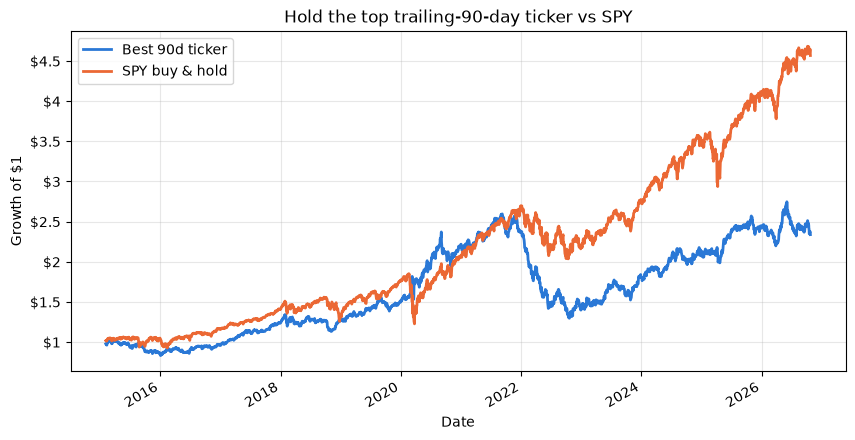

In [16]:
# Shift forward returns onto the day they are earned so both series line up date by date
momentum_rets = pd.DataFrame({
    "Best 90d ticker": best_ticker["fwd_1d_return"].shift(1),
    "SPY buy & hold": close["SPY"].pct_change(),
}).loc[best_ticker.index[1]:]

ax = (1 + momentum_rets).cumprod().plot(figsize=(10, 5), lw=2, color=["#2a78d6", "#eb6834"])
ax.set_title("Hold the top trailing-90-day ticker vs SPY")
ax.set_ylabel("Growth of $1")
ax.yaxis.set_major_formatter("${x:g}")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
days_on_top = best_ticker["ticker"].value_counts().reindex(TICKERS, fill_value=0)
ticker_colors = {"SPY": "#eb6834", "QQQ": "#2a78d6", "TLT": "#1baf7a", "IEF": "#eda100", "GLD": "#e87ba4", "USO": "#8a5cd6", "JNK": "#7a6a55"}

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    days_on_top,
    labels=[f"{t}\n{n:,} days" for t, n in days_on_top.items()],
    colors=[ticker_colors[t] for t in days_on_top.index],
    autopct="%.0f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)
ax.set_title("Share of days each ticker had the top trailing-90-day return")
plt.show()

In [ ]:
# Which ticker actually had the best next-day return, over the same dates as best_ticker
best_fwd_ticker = fwd_1d.loc[best_ticker.index].dropna().idxmax(axis=1)
days_best_fwd = best_fwd_ticker.value_counts().reindex(TICKERS, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    days_best_fwd,
    labels=[f"{t}\n{n:,} days" for t, n in days_best_fwd.items()],
    colors=[ticker_colors[t] for t in days_best_fwd.index],
    autopct="%.0f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)
ax.set_title("Share of days each ticker had the best 1-day forward return")
plt.show()

In [ ]:
def forward_returns(px: pd.DataFrame, horizon: pd.DateOffset) -> pd.DataFrame:
    """Return from each close to the last close on or before (date + horizon)."""
    target = px.index + horizon
    fwd_close = px.reindex(target, method="ffill").set_axis(px.index)
    fwd_close[target > px.index[-1]] = float("nan")  # horizon runs past the data
    return fwd_close / px - 1


HORIZONS = {"1-month": pd.DateOffset(months=1), "3-month": pd.DateOffset(months=3)}

fig, axes = plt.subplots(1, len(HORIZONS), figsize=(12, 6), layout="constrained")
for ax, (name, horizon) in zip(axes, HORIZONS.items()):
    fwd = forward_returns(close, horizon).loc[best_ticker.index].dropna()
    winner = fwd.idxmax(axis=1)
    counts = winner.value_counts().reindex(TICKERS, fill_value=0)
    hit_rate = (winner == best_ticker["ticker"].loc[winner.index]).mean()
    ax.pie(
        counts,
        labels=[f"{t}\n{n:,} days" for t, n in counts.items()],
        colors=[ticker_colors[t] for t in counts.index],
        autopct="%.0f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        textprops={"fontsize": 11},
    )
    ax.set_title(f"Best {name} forward return\n90d leader matched it {hit_rate:.0%} of days")
plt.show()

### 30-day vs 90-day trailing leader

How often does each lookback's leader end up with the best forward return? A random pick is right 1 in N times (about 14% with seven tickers).

In [ ]:
def trailing_leader(px: pd.DataFrame, days: int) -> pd.Series:
    """Ticker with the highest return over the trailing `days` calendar days."""
    past = px.reindex(px.index - pd.Timedelta(days=days), method="ffill").set_axis(px.index)
    return (px / past - 1).dropna().idxmax(axis=1)


# Only dates where every lookback has a leader, so they're scored on the same days
leaders = pd.DataFrame({f"{d}d leader": trailing_leader(close, d) for d in (30, 90)}).dropna()
fwd_by_horizon = {"1-day": fwd_1d} | {name: forward_returns(close, h) for name, h in HORIZONS.items()}

# Share of days the trailing leader also had the best forward return
hit_rates = {}
for horizon, fwd in fwd_by_horizon.items():
    winner = fwd.loc[leaders.index].dropna().idxmax(axis=1)
    hit_rates[horizon] = {name: (leaders.loc[winner.index, name] == winner).mean() for name in leaders}
hit_rates = pd.DataFrame(hit_rates).T

leader_mix = leaders.apply(lambda lead: lead.value_counts(normalize=True)).reindex(TICKERS)

display(hit_rates.style.format("{:.1%}").set_caption("Hit rate vs best forward return"))
display(leader_mix.style.format("{:.0%}").set_caption("Share of days each ticker was the leader"))

In [ ]:
def rebalanced_leader(px: pd.DataFrame, n: int, offset: int = 0) -> tuple[pd.Series, pd.Series]:
    """Hold the trailing-n-day leader, re-picked every n trading days. Returns (daily returns, picks)."""
    period = px.loc[max(best_ticker.index[0], px.index[n]):]  # need n days of history for the first pick
    rebal_dates = period.index[offset::n]
    picks = px.pct_change(n).loc[rebal_dates].idxmax(axis=1)
    held = picks.reindex(period.index, method="ffill").shift(1).dropna()  # position starts the day after the pick
    daily_rets = px.pct_change()
    return pd.Series([daily_rets.at[d, t] for d, t in held.items()], index=held.index), picks


def cagr(rets: pd.Series) -> float:
    return (1 + rets).prod() ** (252 / len(rets)) - 1


def rebalance_backtest(n: int):
    """Chart and summarize the n-day leader strategy against the 90d leader and SPY."""
    rets, picks = rebalanced_leader(close, n)

    # Did each pick have the best return over its n-day holding period?
    block_winner = (close.shift(-n) / close - 1).loc[picks.index].dropna().idxmax(axis=1)
    hit_rate = (picks.loc[block_winner.index] == block_winner).mean()

    # The result depends on which day the rebalance cycle starts, so try every starting day
    offset_cagrs = pd.Series([cagr(rebalanced_leader(close, n, k)[0]) for k in range(n)])

    strategies = momentum_rets.assign(**{f"{n}d leader, rebalanced every {n}d": rets}).dropna()
    ax = (1 + strategies).cumprod().plot(figsize=(10, 5), lw=2, color=["#2a78d6", "#eb6834", "#1baf7a"])
    ax.set_title(f"{n}-day leader rebalanced every {n} days vs 90d leader and SPY")
    ax.set_ylabel("Growth of $1")
    ax.yaxis.set_major_formatter("${x:g}")
    ax.grid(alpha=0.3)
    plt.show()

    print(f"{len(picks)} rebalances, pick had the best next-{n}-day return {hit_rate:.1%} of the time")
    print(f"Annual return across all {n} starting days: median {offset_cagrs.median():.1%}, "
          f"range {offset_cagrs.min():.1%} to {offset_cagrs.max():.1%}")
    growth = (1 + strategies).prod()
    return pd.DataFrame({"Growth of $1": growth, "Annual return": strategies.apply(cagr)}).style.format(
        {"Growth of $1": "${:.2f}", "Annual return": "{:.1%}"}
    )


rebalance_backtest(10)

In [ ]:
rebalance_backtest(30)

### Month-end rebalance with a trailing stop

At each month end, buy the ticker with the best trailing 3-month (or 6-month) return and hold it to the next month end. With the stop on, if the close falls 7% below its highest close since entry, sell at that close and sit in cash (0% return) until the next month end.

In [ ]:
STOP = 0.07  # trailing stop, from the highest close since entry

month_ends = close.groupby(close.index.to_period("M")).tail(1).index
month_ends = month_ends[month_ends < close.index[-1]]  # the current month isn't over yet


def month_end_leader(
    px: pd.DataFrame, months: int, stop: float | None = None, allow_short: bool = False
) -> tuple[pd.Series, pd.Series, pd.Series]:
    """Hold the trailing-`months` leader from each month end to the next. Returns (daily returns, picks, stopped out).

    With `allow_short`, a leader whose trailing return is negative is shorted for the month instead.
    """
    trailing = px.loc[month_ends].pct_change(months).dropna()
    picks = trailing.idxmax(axis=1)
    short = allow_short & (trailing.max(axis=1) < 0)
    period_ends = list(picks.index[1:]) + [px.index[-1]]
    rets, stopped = [], {}
    for start, end, t in zip(picks.index, period_ends, picks):
        path = px.loc[start:end, t]
        if short[start]:
            path = 2 - path / path.iloc[0]  # value of a short opened at the month-end close
        r = path.pct_change().iloc[1:]
        hit = (path / path.cummax() - 1).iloc[1:] <= -stop if stop else pd.Series(False, index=r.index)
        if hit.any():
            r[r.index > hit.idxmax()] = 0.0  # out at the close of the stop day, cash after
        stopped[start] = hit.any()
        rets.append(r)
    return pd.concat(rets), picks, pd.Series(stopped)


# Did the pick have the best return over the following month?
next_month_winner = close.loc[month_ends].pct_change().shift(-1).dropna().idxmax(axis=1)

runs, stats = {}, {}
for months in (3, 6):
    for stop in (STOP, None):
        label = f"{months}m leader" + (f" + {stop:.0%} stop" if stop else ", no stop")
        runs[label], picks, stopped = month_end_leader(close, months, stop)
        stats[label] = {
            "Months stopped out": f"{stopped.sum()} of {len(stopped)}" if stop else "",
            "Pick hit rate": (picks.reindex(next_month_winner.index) == next_month_winner).loc[picks.index[0]:].mean(),
        }

month_end_rets = pd.DataFrame(runs).assign(**{"SPY buy & hold": close["SPY"].pct_change()}).dropna()
growth_curves = (1 + month_end_rets).cumprod()

ax = growth_curves.plot(
    figsize=(10, 5), lw=2,
    color=["#2a78d6", "#2a78d6", "#1baf7a", "#1baf7a", "#eb6834"],
    style=["-", "--", "-", "--", "-"],
)
ax.set_title(f"Month-end leader, 3m vs 6m lookback, with and without a {STOP:.0%} trailing stop")
ax.set_ylabel("Growth of $1")
ax.yaxis.set_major_formatter("${x:g}")
ax.grid(alpha=0.3)
plt.show()

summary_month_end = pd.DataFrame({
    "Growth of $1": growth_curves.iloc[-1],
    "Annual return": month_end_rets.apply(cagr),
    "Max drawdown": (growth_curves / growth_curves.cummax() - 1).min(),
}).join(pd.DataFrame(stats).T)
summary_month_end.style.format(
    {"Growth of $1": "${:.2f}", "Annual return": "{:.1%}", "Max drawdown": "{:.1%}", "Pick hit rate": "{:.1%}"},
    na_rep="",
)

In [ ]:
two_m_rets, two_m_picks, _ = month_end_leader(close, 2)
two_m_hit_rate = (two_m_picks.reindex(next_month_winner.index) == next_month_winner).loc[two_m_picks.index[0]:].mean()

# Same start date as the 3m/6m runs above (the 6m lookback needs the most history)
no_stop = month_end_rets[["3m leader, no stop", "6m leader, no stop", "SPY buy & hold"]].assign(
    **{"2m leader, no stop": two_m_rets}
).dropna()
no_stop_curves = (1 + no_stop).cumprod()

ax = no_stop_curves.plot(figsize=(10, 5), lw=2, color=["#2a78d6", "#1baf7a", "#eb6834", "#eda100"])
ax.set_title("Month-end leader, 2m vs 3m vs 6m lookback, no stop")
ax.set_ylabel("Growth of $1")
ax.yaxis.set_major_formatter("${x:g}")
ax.grid(alpha=0.3)
plt.show()

print(f"2m pick had the best next-month return {two_m_hit_rate:.1%} of {len(two_m_picks)} months")
pd.DataFrame({
    "Growth of $1": no_stop_curves.iloc[-1],
    "Annual return": no_stop.apply(cagr),
    "Max drawdown": (no_stop_curves / no_stop_curves.cummax() - 1).min(),
}).style.format({"Growth of $1": "${:.2f}", "Annual return": "{:.1%}", "Max drawdown": "{:.1%}"})

### Every lookback from 1 to 12 months

Month-end rebalance into the trailing leader, no stop. All lookbacks are scored on the same dates, starting once the 12-month lookback has enough history.

In [ ]:
from matplotlib.ticker import PercentFormatter

BENCHMARKS = {"SPY": "#eb6834", "QQQ": "#2a78d6"}  # buy & hold, with their chart colors


def lookback_comparison(allow_short: bool = False, lookbacks=range(1, 13)):
    """Month-end leader for each lookback (months), scored over the same dates, vs buy & hold benchmarks."""
    rets, picks_by = {}, {}
    for m in lookbacks:
        rets[f"{m}m"], picks_by[f"{m}m"], _ = month_end_leader(close, m, allow_short=allow_short)

    # Score every lookback over the same months: from the longest lookback's first pick onward
    first_pick = picks_by[f"{max(lookbacks)}m"].index[0]
    all_rets = pd.DataFrame(rets).assign(**{f"{t} buy & hold": close[t].pct_change() for t in BENCHMARKS}).dropna()
    curves = (1 + all_rets).cumprod()
    years = len(all_rets) / 252

    trailing_best = {m: close.loc[month_ends].pct_change(m).max(axis=1).loc[first_pick:] for m in lookbacks}
    summary = pd.DataFrame({
        "Growth of $1": curves.iloc[-1],
        "Annual return": all_rets.apply(cagr),
        "Max drawdown": (curves / curves.cummax() - 1).min(),
        "Pick hit rate": {
            name: (p.loc[first_pick:].reindex(next_month_winner.index) == next_month_winner).loc[first_pick:].mean()
            for name, p in picks_by.items()
        },
        "Ticker changes / yr": {
            name: (p.loc[first_pick:] != p.loc[first_pick:].shift()).iloc[1:].sum() / years
            for name, p in picks_by.items()
        },
        "Months short": {f"{m}m": (b < 0).mean() for m, b in trailing_best.items()} if allow_short else {},
    }).reindex(all_rets.columns)  # keep 1m..12m order
    if not allow_short:
        summary = summary.drop(columns="Months short")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    for ax, col in zip(axes, ["Annual return", "Max drawdown"]):
        values = summary[col].drop([f"{t} buy & hold" for t in BENCHMARKS])
        ax.bar(values.index, values, color="#9a9a9a", width=0.7)
        for t, color in BENCHMARKS.items():
            bench = summary.at[f"{t} buy & hold", col]
            ax.axhline(bench, color=color, lw=2, ls="--", label=f"{t} buy & hold ({bench:.1%})")
        if col == "Annual return":
            top = max(values.max(), *(summary.at[f"{t} buy & hold", col] for t in BENCHMARKS))
            ax.set_ylim(top=top * 1.25)  # headroom for the legend
        ax.legend(loc="upper left" if col == "Annual return" else "lower right")  # open space in each chart
        ax.axhline(0, color="#888", lw=0.8)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_xlabel("Trailing lookback")
        ax.set_title(f"{col} by lookback" + (" (short when leader is negative)" if allow_short else ""))
        ax.grid(axis="y", alpha=0.3)
    plt.show()

    print(f"{', '.join(TICKERS)} | scored from {all_rets.index[0]:%Y-%m-%d} to {all_rets.index[-1]:%Y-%m-%d}")
    return summary.style.format({
        "Growth of $1": "${:.2f}", "Annual return": "{:.1%}", "Max drawdown": "{:.1%}",
        "Pick hit rate": "{:.1%}", "Ticker changes / yr": "{:.1f}", "Months short": "{:.0%}",
    }, na_rep="")


lookback_comparison()

### Same, but short a negative leader

If even the best ticker's trailing return is negative at month end, short it for the month instead of buying it. Short P&L is measured on the month-end entry price; borrow costs and interest on cash are ignored.

In [ ]:
lookback_comparison(allow_short=True)

In [ ]:
import matplotlib.dates as mdates

# Growth of $1 for every lookback, long-only and with shorts, against the buy & hold benchmarks
lookback_growth = pd.concat({
    "Long only": pd.DataFrame({f"{m}m": month_end_leader(close, m)[0] for m in range(1, 13)}),
    "Short when leader negative": pd.DataFrame({f"{m}m": month_end_leader(close, m, allow_short=True)[0] for m in range(1, 13)}),
    "Benchmark": pd.DataFrame({t: close[t].pct_change() for t in BENCHMARKS}),
}, axis=1, sort=True).dropna()  # same dates as the tables above
lookback_growth = (1 + lookback_growth).cumprod()

fig, axes = plt.subplots(3, 4, figsize=(14, 9), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes.flat, lookback_growth["Long only"].columns):
    for t, color in BENCHMARKS.items():
        ax.plot(lookback_growth[("Benchmark", t)], color=color, lw=1.2, ls="--", label=f"{t} buy & hold")
    ax.plot(lookback_growth[("Long only", name)], color="#555555", lw=2, label="Long only")
    ax.plot(lookback_growth[("Short when leader negative", name)], color="#1baf7a", lw=2, label="Short when leader negative")
    ax.set_title(f"{name} lookback")
    ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter("${x:g}")  # shared across panels
ax.xaxis.set_major_locator(mdates.YearLocator(3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle(f"Growth of $1, month-end leader of {', '.join(TICKERS)}")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
plt.show()

### Rank on the moving average instead of the close

At each month end, compute each ticker's 20-, 50- and 200-day simple moving average and rank tickers by that SMA's % change over a trailing window of 15 to 180 calendar days. Ranking on the raw close is included as the unsmoothed baseline. Two portfolios are built from the ranking and held to the next month end (long only, no stop):

- **Top 1**: 100% in the top-ranked ticker.
- **Top 3 mix**: 50% / 30% / 20% in the top three, set at the month end and left to drift with prices until the next one.

Returns are earned on the actual close; the SMA only drives the ranking. Every combination is scored over the same dates, starting once the 200-day SMA with a 180-day lookback has enough history.

In [ ]:
SMA_WINDOWS = (20, 50, 200)  # trading days
SMA_LOOKBACKS = (15, 30, 60, 90, 120, 150, 180)  # calendar days over which each SMA's % change is ranked
PORTFOLIOS = {"Top 1": (1.0,), "Top 3 mix": (0.5, 0.3, 0.2)}  # weights by rank


def trailing_change(signal: pd.DataFrame, days: int) -> pd.DataFrame:
    """% change of `signal` over the trailing `days` calendar days, at each month end."""
    # Value on the last trading day on or before (month end - days)
    past = signal.reindex(signal.index - pd.Timedelta(days=days), method="ffill").set_axis(signal.index)
    return (signal / past - 1).loc[month_ends].dropna()


def month_end_mix(
    px: pd.DataFrame, signal: pd.DataFrame, days: int, weights: tuple[float, ...]
) -> tuple[pd.Series, pd.DataFrame]:
    """Hold the top-ranked tickers from each month end to the next, weighted by rank. Returns (daily returns, picks).

    Tickers are ranked by `signal`'s % change over the trailing `days` calendar days ending at the month end.
    Weights are set at each month end and drift with prices until the next one. Returns are earned on `px`.
    `picks` has one column per rank (0 = leader).
    """
    trailing = trailing_change(signal, days)
    picks = pd.DataFrame([row.nlargest(len(weights)).index for _, row in trailing.iterrows()], index=trailing.index)
    period_ends = list(picks.index[1:]) + [px.index[-1]]
    rets = []
    for start, end, held in zip(picks.index, period_ends, picks.itertuples(index=False)):
        path = px.loc[start:end, list(held)]
        value = (path / path.iloc[0]).mul(list(weights)).sum(axis=1)  # bought at the month-end close, then drifts
        rets.append(value.pct_change().iloc[1:])
    return pd.concat(rets), picks


# Rank on the raw close too, as the no-smoothing baseline
signals = {"Close": close} | {f"{n}d SMA": close.rolling(n).mean() for n in SMA_WINDOWS}
signal_colors = {"Close": "#555555", "20d SMA": "#1baf7a", "50d SMA": "#eda100", "200d SMA": "#e87ba4"}

sma_runs, sma_leaders = {}, {}
for port, weights in PORTFOLIOS.items():
    for name, signal in signals.items():
        for days in SMA_LOOKBACKS:
            sma_runs[port, name, days], picks = month_end_mix(close, signal, days, weights)
            sma_leaders[name, days] = picks[0]  # the ranking, and so the leader, is the same for every portfolio

# Score every combination over the same months: from the latest first pick (200d SMA, 180-day lookback) onward
first_pick = max(p.index[0] for p in sma_leaders.values())
sma_rets = pd.DataFrame(sma_runs).dropna()
bench_rets = pd.DataFrame({t: close[t].pct_change() for t in BENCHMARKS}).loc[sma_rets.index]
years = len(sma_rets) / 252


def risk_return(rets: pd.DataFrame) -> pd.DataFrame:
    """Growth of $1, annual return, max drawdown and annualized volatility for each column of daily returns."""
    curves = (1 + rets).cumprod()
    return pd.DataFrame({
        "Growth of $1": curves.iloc[-1],
        "Annual return": rets.apply(cagr),
        "Max drawdown": (curves / curves.cummax() - 1).min(),
        "Volatility": rets.std() * 252**0.5,
    })


sma_summary = risk_return(sma_rets)
bench_summary = risk_return(bench_rets)
leader_stats = pd.DataFrame({
    "Pick hit rate": pd.Series({
        key: (p.reindex(next_month_winner.index) == next_month_winner).loc[first_pick:].mean()
        for key, p in sma_leaders.items()
    }),
    "Ticker changes / yr": pd.Series({
        key: (p.loc[first_pick:] != p.loc[first_pick:].shift()).iloc[1:].sum() / years
        for key, p in sma_leaders.items()
    }),
})

METRICS = ["Annual return", "Max drawdown", "Volatility"]


def plot_sma_grid(summary: pd.DataFrame, title: str) -> None:
    """Grouped bars: one row per metric, one column per portfolio; one group per lookback, one bar per signal.

    `summary` is indexed by (portfolio, signal, lookback days) with one column per metric.
    """
    ports = summary.index.unique(0)  # in the order given
    summary = summary.sort_index()  # sorted so .loc[port] is fast
    fig, axes = plt.subplots(len(METRICS), len(ports), figsize=(16, 12), sharey="row", layout="constrained")
    width = 0.8 / len(signals)
    for row, col in zip(axes, METRICS):
        for ax, port in zip(row, ports):
            by_lookback = summary.loc[port, col].unstack(0)  # rows: lookback days, columns: signal
            for i, name in enumerate(signals):
                x = [k + (i - (len(signals) - 1) / 2) * width for k in range(len(SMA_LOOKBACKS))]
                ax.bar(x, by_lookback[name], width, color=signal_colors[name], label=name)
            for t, color in BENCHMARKS.items():
                ax.axhline(bench_summary.at[t, col], color=color, lw=2, ls="--", label=f"{t} buy & hold")
            ax.set_xticks(range(len(SMA_LOOKBACKS)), [f"{d}d" for d in SMA_LOOKBACKS])
            ax.axhline(0, color="#888", lw=0.8)
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.set_title(f"{port}: {col.lower()}")
            ax.grid(axis="y", alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Trailing lookback for the % change (calendar days)")
    fig.suptitle(title)
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=6)
    plt.show()


plot_sma_grid(sma_summary, f"Month-end leaders of {', '.join(TICKERS)}, ranked on close vs 20/50/200-day SMA")

print(f"{', '.join(TICKERS)} | scored from {sma_rets.index[0]:%Y-%m-%d} to {sma_rets.index[-1]:%Y-%m-%d}")
display(bench_summary.style.format({"Growth of $1": "${:.2f}", "Annual return": "{:.1%}", "Max drawdown": "{:.1%}",
                                   "Volatility": "{:.1%}"}).set_caption("Buy & hold benchmarks"))
rows = pd.MultiIndex.from_product([list(PORTFOLIOS), list(signals)])
for col in METRICS:
    table = sma_summary[col].unstack(2).reindex(rows)  # rows: (portfolio, signal), columns: lookback days
    display(table.rename(columns=lambda d: f"{d}d").style.format("{:.1%}").set_caption(col))
for col, fmt in {"Pick hit rate": "{:.1%}", "Ticker changes / yr": "{:.1f}"}.items():
    table = leader_stats[col].unstack(1).loc[list(signals)]  # rows: signal, columns: lookback days
    display(table.rename(columns=lambda d: f"{d}d").style.format(fmt).set_caption(f"{col} (top-ranked ticker)"))

### Long the top 3, short the losers

Same ranking as above (each signal's % change over each trailing lookback, at month end). The long leg is the top 3 at 50% / 30% / 20%, as in the top 3 mix. The short leg is every other ticker whose trailing change is negative, in equal weights adding up to 100%; with no negative tickers the month is long only. A ticker in the top 3 is never also shorted.

Both legs are sized off the month-end capital and drift with prices until the next month end. Short P&L is measured on the month-end entry price; borrow costs and interest on short proceeds are ignored. Scored over the same dates as the grid above.

In [ ]:
LS_PORT = "Long top 3, short negatives"


def month_end_long_short(
    px: pd.DataFrame, signal: pd.DataFrame, days: int, long_weights: tuple[float, ...]
) -> tuple[pd.Series, pd.Series]:
    """Long the top-ranked tickers by rank weight, short the other negative ones equally. Returns (daily returns, shorts).

    Ranking is `signal`'s % change over the trailing `days` calendar days at each month end. The long leg is
    100% of month-end capital split by `long_weights`; the short leg is 100% split equally across every ticker
    outside the long leg whose trailing change is negative (no short leg if there are none). Both legs drift
    with prices until the next month end. `shorts` is the number of tickers shorted in each month.
    """
    trailing = trailing_change(signal, days)
    period_ends = list(trailing.index[1:]) + [px.index[-1]]
    rets, shorts = [], {}
    for (start, row), end in zip(trailing.iterrows(), period_ends):
        longs = row.nlargest(len(long_weights)).index
        short = row.index[(row < 0) & ~row.index.isin(longs)]
        moved = px.loc[start:end] / px.loc[start] - 1  # each ticker's cumulative return since the month-end close
        value = 1 + moved[longs].mul(list(long_weights)).sum(axis=1)
        if len(short):
            value -= moved[short].mean(axis=1)  # equal weights summing to 100%; gains when those prices fall
        rets.append(value.pct_change().iloc[1:])
        shorts[start] = len(short)
    return pd.concat(rets), pd.Series(shorts)


ls_runs, ls_shorts = {}, {}
for name, signal in signals.items():
    for days in SMA_LOOKBACKS:
        ls_runs[name, days], ls_shorts[name, days] = month_end_long_short(close, signal, days, PORTFOLIOS["Top 3 mix"])

ls_rets = pd.DataFrame(ls_runs).loc[sma_rets.index]  # same dates as the long-only grid
ls_vs_mix = pd.concat({"Top 3 mix": sma_summary.loc["Top 3 mix"], LS_PORT: risk_return(ls_rets)})
short_stats = pd.DataFrame({
    "Months with a short": pd.Series({key: (s.loc[first_pick:] > 0).mean() for key, s in ls_shorts.items()}),
    "Avg tickers shorted": pd.Series({key: s.loc[first_pick:].mean() for key, s in ls_shorts.items()}),
})

plot_sma_grid(ls_vs_mix, f"Top 3 mix, long only vs also shorting negative tickers ({', '.join(TICKERS)})")

print(f"{', '.join(TICKERS)} | scored from {ls_rets.index[0]:%Y-%m-%d} to {ls_rets.index[-1]:%Y-%m-%d}")
rows = pd.MultiIndex.from_product([["Top 3 mix", LS_PORT], list(signals)])
for col in METRICS:
    table = ls_vs_mix[col].unstack(2).reindex(rows)  # rows: (portfolio, signal), columns: lookback days
    display(table.rename(columns=lambda d: f"{d}d").style.format("{:.1%}").set_caption(col))
for col, fmt in {"Months with a short": "{:.0%}", "Avg tickers shorted": "{:.1f}"}.items():
    table = short_stats[col].unstack(1).loc[list(signals)]  # rows: signal, columns: lookback days
    display(table.rename(columns=lambda d: f"{d}d").style.format(fmt).set_caption(col))

# Backtest: moving-average crossover

Long when the fast SMA is above the slow SMA, otherwise in cash. Signals are lagged one day so each trade uses only information available at the prior close.

In [ ]:
FAST = 50
SLOW = 200
COST_BPS = 5  # one-way transaction cost in basis points
TRADING_DAYS = 252

In [ ]:
def sma_crossover(px: pd.Series, fast: int, slow: int, cost_bps: float) -> pd.DataFrame:
    rets = px.pct_change().fillna(0)
    signal = (px.rolling(fast).mean() > px.rolling(slow).mean()).astype(int)
    position = signal.shift(1).fillna(0)  # trade at next bar, no lookahead
    costs = position.diff().abs().fillna(0) * cost_bps / 10_000
    strat = position * rets - costs
    return pd.DataFrame({"position": position, "buy_hold": rets, "strategy": strat})


def performance(rets: pd.Series) -> pd.Series:
    equity = (1 + rets).cumprod()
    years = len(rets) / TRADING_DAYS
    vol = rets.std() * TRADING_DAYS**0.5
    return pd.Series({
        "Total return": equity.iloc[-1] - 1,
        "CAGR": equity.iloc[-1] ** (1 / years) - 1,
        "Volatility": vol,
        "Sharpe": rets.mean() * TRADING_DAYS / vol if vol else float("nan"),
        "Max drawdown": (equity / equity.cummax() - 1).min(),
    })

In [ ]:
results = {t: sma_crossover(close[t], FAST, SLOW, COST_BPS) for t in TICKERS}

summary = pd.concat(
    {(t, col): performance(r[col]) for t, r in results.items() for col in ("buy_hold", "strategy")},
    axis=1,
)
summary.style.format("{:.2%}").format("{:.2f}", subset=pd.IndexSlice["Sharpe", :])

In [ ]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(10, 3.5 * len(TICKERS)), sharex=True)
for ax, t in zip(axes, TICKERS):
    r = results[t]
    (1 + r[["buy_hold", "strategy"]]).cumprod().plot(ax=ax, logy=True)
    ax.set_title(f"{t}: SMA {FAST}/{SLOW} vs buy & hold")
    ax.set_ylabel("Growth of $1")
plt.tight_layout()
plt.show()